# PMU–DRL — First manuscript revision: fixed YOLOv4 case study

This notebook implements the **first revision stage** agreed after the input-trace audit.

Current evidence state from the author feedback:

- `data1`: only **PPO seed 1024** is currently confirmed against `lynsyn_data1.txt`.
- `data1`: PPO seeds 200/345/789/999 and all five seeds for DDPG, SAC, TD3 and TRPO are **pending** — 24 combinations in total.
- `data2` and `data3`: the present input-mapping checks passed.
- Correcting an **evaluation** trace does not establish which trace was used for **training**. Training and evaluation provenance are therefore kept separate.

The notebook is deliberately conservative. Cross-algorithm statistical summaries are generated only from datasets for which **all expected algorithm–seed evaluation combinations are verified**. With the current audit, this means `data2` and `data3`. The verified `data1/PPO/1024` result is reported separately and is not used to create an unbalanced cross-algorithm comparison.

The first-revision outputs cover:

1. evaluation-trace completion audit;
2. physically measured baseline-trace analysis;
3. source-to-simulator-controlled comparisons on a common verified subset;
4. interim five-seed mean/SD/95% CI and paired statistics;
5. multi-seed training reward and **adjusted efficiency** (`epoch_mean_efficiency × percentage`) figures;
6. conditional controller-overhead break-even bounds;
7. a first-revision claim table identifying what can already be written and what must remain narrowed/removed.

No result in this notebook should be described as cross-resolution, cross-CNN, cross-hardware, physical controlled-power, measured controller overhead, measured FPS/latency preservation, or a causal CPU/GPU/reward ablation.

## 1. Imports, project discovery and output folders

In [1]:
from pathlib import Path
from itertools import combinations, product
import ast
import csv
import io
import json
import math
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    from IPython.display import display
except Exception:
    display = print

ROOT = Path(os.environ.get("PMUDRL_ROOT", Path.cwd())).resolve()
EXPECTED_SEEDS = [200, 345, 789, 999, 1024]
EXPECTED_ALGORITHMS = ["ddpg", "ppo", "sac", "td3", "trpo"]

def natural_key(path):
    m = re.search(r"(\d+)$", path.name)
    return (path.name[:m.start()] if m else path.name,
            int(m.group(1)) if m else -1)

DATASET_ROOTS = {
    p.name: p
    for p in sorted(
        [q for q in ROOT.iterdir()
         if q.is_dir() and re.fullmatch(r"data\d+", q.name, re.I)],
        key=natural_key
    )
}

RAW_TRACE_BY_DATASET = {}
for dataset in DATASET_ROOTS:
    m = re.search(r"(\d+)$", dataset)
    candidate = ROOT / f"lynsyn_data{m.group(1)}.txt" if m else None
    RAW_TRACE_BY_DATASET[dataset] = candidate if candidate and candidate.exists() else None

REFERENCE_NOTEBOOK_CANDIDATES = [
    ROOT / "analysis_all.ipynb",
    ROOT / "analysis_all_expanded.ipynb",
]
REFERENCE_NOTEBOOK = next((p for p in REFERENCE_NOTEBOOK_CANDIDATES if p.exists()), None)

print("Project root:", ROOT)
print("Discovered datasets:", list(DATASET_ROOTS))
print("Expected seeds:", EXPECTED_SEEDS)
print("Expected algorithms:", EXPECTED_ALGORITHMS)
print("Reference notebook:", REFERENCE_NOTEBOOK if REFERENCE_NOTEBOOK else "NOT FOUND")

OUTPUT_ROOT = ROOT / "revision1_fixed_yolov4_analysis"
TABLE_ROOT = OUTPUT_ROOT / "tables"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
for p in (OUTPUT_ROOT, TABLE_ROOT, FIGURE_ROOT):
    p.mkdir(parents=True, exist_ok=True)
print("Outputs:", OUTPUT_ROOT)

Project root: /home/pedro/repo/Zheqi_Results/test
Discovered datasets: ['data1', 'data2', 'data3']
Expected seeds: [200, 345, 789, 999, 1024]
Expected algorithms: ['ddpg', 'ppo', 'sac', 'td3', 'trpo']
Reference notebook: /home/pedro/repo/Zheqi_Results/test/analysis_all.ipynb
Outputs: /home/pedro/repo/Zheqi_Results/test/revision1_fixed_yolov4_analysis


## 2. Recover the legacy result-file schema without inventing CSV headers

The supplied `*_power.csv` files are legacy headerless exports. Their semantic schema is recovered from the original `analysis_all.ipynb`, where the files were read with an explicit `names=[...]` list. Headered CSVs use their own row-1 headers.

If the original notebook is unavailable, semantic analyses of headerless result files are skipped rather than silently assigning invented meanings.

In [2]:
def normalise_colname(name):
    text = str(name).replace("\ufeff", "").strip()
    text = re.sub(r"[^0-9A-Za-z]+", "_", text).strip("_").lower()
    return text or "unnamed"

def extract_power_schema_from_notebook(path):
    if path is None or not Path(path).exists():
        return None, "reference notebook not found"

    try:
        notebook = json.loads(Path(path).read_text(encoding="utf-8"))
    except Exception as exc:
        return None, f"could not read reference notebook: {exc}"

    candidates = []
    for cell in notebook.get("cells", []):
        if cell.get("cell_type") != "code":
            continue
        source = "".join(cell.get("source", []))
        if "_power" not in source or "pd.read_csv" not in source or "names=" not in source:
            continue
        for match in re.finditer(r"names\s*=\s*(\[[\s\S]*?\])", source):
            try:
                value = ast.literal_eval(match.group(1))
            except Exception:
                continue
            if isinstance(value, list) and value and all(isinstance(x, str) for x in value):
                norm = [normalise_colname(x) for x in value]
                if "observation_new" in norm and "source_power_data" in norm:
                    candidates.append(norm)

    if not candidates:
        return None, "no result-power schema recovered from reference notebook"

    counts = {}
    for candidate in candidates:
        key = tuple(candidate)
        counts[key] = counts.get(key, 0) + 1
    best = list(max(counts, key=counts.get))
    return best, f"extracted from {Path(path).name}"

POWER_SCHEMA, POWER_SCHEMA_SOURCE = extract_power_schema_from_notebook(REFERENCE_NOTEBOOK)
print("Recovered result-power schema:", POWER_SCHEMA)
print("Schema provenance:", POWER_SCHEMA_SOURCE)

def inspect_csv_layout(path, sample_bytes=65536):
    path = Path(path)
    with path.open("r", encoding="utf-8", errors="replace") as fh:
        text = fh.read(sample_bytes)

    if not text.strip():
        return {"delimiter": ",", "has_header": False, "field_count": 0, "first_row": []}

    first_line = text.splitlines()[0] if text.splitlines() else ""
    delimiter_counts = {d: first_line.count(d) for d in [";", ",", "\t", "|"]}
    delimiter = max(delimiter_counts, key=delimiter_counts.get)
    if delimiter_counts[delimiter] == 0:
        try:
            delimiter = csv.Sniffer().sniff(text, delimiters=",;\t|").delimiter
        except Exception:
            delimiter = ","

    try:
        has_header = bool(csv.Sniffer().has_header(text))
    except Exception:
        has_header = False

    first_row = next(csv.reader(io.StringIO(text), delimiter=delimiter), [])
    return {
        "delimiter": delimiter,
        "has_header": has_header,
        "field_count": len(first_row),
        "first_row": first_row,
    }

def read_project_csv(path, *, nrows=None):
    path = Path(path)
    layout = inspect_csv_layout(path)
    delimiter = layout["delimiter"]
    field_count = layout["field_count"]

    if layout["has_header"]:
        df = pd.read_csv(path, sep=delimiter, header=0, nrows=nrows)
        raw_headers = [str(x).replace("\ufeff", "").strip() for x in df.columns]
        columns = [normalise_colname(x) for x in raw_headers]
        schema_source = "row_1_header"
        omitted_source_fields = []
    else:
        raw_headers = []
        if POWER_SCHEMA is not None and path.name.endswith("_power.csv") and len(POWER_SCHEMA) >= field_count:
            columns = POWER_SCHEMA[:field_count]
            omitted_source_fields = POWER_SCHEMA[field_count:]
            schema_source = POWER_SCHEMA_SOURCE
        else:
            columns = [f"column_{i}" for i in range(field_count)]
            omitted_source_fields = []
            schema_source = "neutral positional labels; semantic schema unavailable"
        df = pd.read_csv(path, sep=delimiter, header=None, names=columns, nrows=nrows)

    if len(set(columns)) != len(columns):
        raise ValueError(f"{path}: duplicate column names after normalisation: {columns}")

    df.attrs["raw_headers"] = raw_headers
    df.attrs["normalised_headers"] = columns
    df.attrs["has_header"] = layout["has_header"]
    df.attrs["schema_source"] = schema_source
    df.attrs["omitted_source_fields"] = omitted_source_fields
    return df

def numeric(series):
    return pd.to_numeric(series, errors="coerce")

def t_ci(values, level=0.95):
    x = pd.Series(values, dtype="float64").dropna().to_numpy()
    if len(x) == 0:
        return np.nan, np.nan
    if len(x) == 1:
        return float(x[0]), float(x[0])
    q = stats.t.ppf((1 + level) / 2, len(x) - 1)
    se = stats.sem(x)
    return float(np.mean(x) - q * se), float(np.mean(x) + q * se)

def exact_signflip_pvalue(diff):
    d = pd.Series(diff, dtype="float64").dropna().to_numpy()
    if len(d) < 2:
        return np.nan
    observed = abs(d.mean())
    values = []
    for signs in product([-1.0, 1.0], repeat=len(d)):
        values.append(abs(np.mean(d * np.asarray(signs))))
    return float(np.mean(np.asarray(values) >= observed - 1e-15))

def holm_adjust(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full(len(p), np.nan)
    valid = np.where(np.isfinite(p))[0]
    if not len(valid):
        return out
    order = valid[np.argsort(p[valid])]
    running = 0.0
    m = len(order)
    for rank, idx in enumerate(order):
        adjusted = min(1.0, (m - rank) * p[idx])
        running = max(running, adjusted)
        out[idx] = running
    return out

Recovered result-power schema: ['episode_length', 'action', 'reward', 'all_reward', 'observation_new', 'source_power_data', 'efficiency', 'cpu_count', 'gpu_count', 'flag_min_efficiency']
Schema provenance: extracted from analysis_all.ipynb


## 3. Evaluation-trace audit and Data 1 completion gate

In [3]:
# Evaluation-trace verification state from Zheqi's audit.
#
# Default state from the feedback:
#   * data1: only PPO seed 1024 has been confirmed against lynsyn_data1.txt.
#   * data1: the other 24 algorithm-seed combinations remain pending.
#   * data2 and data3: current input-mapping checks passed.
#
# If ROOT/evaluation_trace_verification.csv exists, it overrides these defaults.
# Required columns in an override file:
# dataset, seed, algorithm, verification_status
# Optional columns:
# intended_evaluation_trace, notes
#
# Accepted verification_status values: verified, pending, rejected.

rows = []
for dataset in DATASET_ROOTS:
    trace_name = RAW_TRACE_BY_DATASET.get(dataset)
    intended_trace = trace_name.name if trace_name else ""
    for seed in EXPECTED_SEEDS:
        for algorithm in EXPECTED_ALGORITHMS:
            if dataset.lower() == "data1":
                status = "verified" if (algorithm == "ppo" and seed == 1024) else "pending"
                note = (
                    "Confirmed against Trace 1"
                    if status == "verified"
                    else "Must be recovered or re-evaluated using intended Trace 1 input"
                )
            elif dataset.lower() in {"data2", "data3"}:
                status = "verified"
                note = "Input-mapping check passed according to author feedback"
            else:
                status = "pending"
                note = "No trace-verification statement available"
            power_path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_power.csv"
            efficiency_path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_efficiency.csv"
            rows.append({
                "dataset": dataset,
                "seed": seed,
                "algorithm": algorithm,
                "intended_evaluation_trace": intended_trace,
                "verification_status": status,
                "power_file_present": power_path.exists(),
                "efficiency_file_present": efficiency_path.exists(),
                "notes": note,
            })

evaluation_trace_audit = pd.DataFrame(rows)

override_path = ROOT / "evaluation_trace_verification.csv"
if override_path.exists():
    override = pd.read_csv(override_path)
    required = {"dataset", "seed", "algorithm", "verification_status"}
    if not required.issubset(override.columns):
        raise ValueError(
            f"{override_path} must contain {sorted(required)}; "
            f"found {list(override.columns)}"
        )
    override["dataset"] = override["dataset"].astype(str)
    override["algorithm"] = override["algorithm"].astype(str).str.lower()
    override["seed"] = pd.to_numeric(override["seed"], errors="raise").astype(int)
    override["verification_status"] = override["verification_status"].astype(str).str.lower()
    allowed = {"verified", "pending", "rejected"}
    bad = sorted(set(override["verification_status"]) - allowed)
    if bad:
        raise ValueError(f"Unsupported verification_status values: {bad}")
    key = ["dataset", "seed", "algorithm"]
    base = evaluation_trace_audit.set_index(key)
    ov = override.set_index(key)
    for col in ["verification_status", "intended_evaluation_trace", "notes"]:
        if col in ov.columns:
            base.loc[base.index.intersection(ov.index), col] = ov.loc[
                base.index.intersection(ov.index), col
            ]
    evaluation_trace_audit = base.reset_index()
    print("Applied evaluation-trace verification overrides from:", override_path)

evaluation_trace_audit["eligible_for_evaluation_analysis"] = (
    evaluation_trace_audit["verification_status"].eq("verified")
    & evaluation_trace_audit["power_file_present"]
)

evaluation_trace_audit.to_csv(TABLE_ROOT / "evaluation_trace_audit.csv", index=False)

template = evaluation_trace_audit[
    ["dataset", "seed", "algorithm", "intended_evaluation_trace",
     "verification_status", "notes"]
].copy()
template.to_csv(TABLE_ROOT / "evaluation_trace_verification_template.csv", index=False)

display(evaluation_trace_audit)

pending = evaluation_trace_audit[
    evaluation_trace_audit["verification_status"].ne("verified")
]
print("Pending/rejected combinations:", len(pending))
if not pending.empty:
    display(pending[["dataset", "seed", "algorithm", "verification_status", "notes"]])

def dataset_is_fully_verified(dataset):
    subset = evaluation_trace_audit[evaluation_trace_audit["dataset"] == dataset]
    expected_n = len(EXPECTED_SEEDS) * len(EXPECTED_ALGORITHMS)
    return (
        len(subset) == expected_n
        and subset["eligible_for_evaluation_analysis"].all()
    )

FULLY_VERIFIED_DATASETS = [
    d for d in DATASET_ROOTS if dataset_is_fully_verified(d)
]
print("Fully verified datasets:", FULLY_VERIFIED_DATASETS)

,dataset,seed,algorithm,intended_evaluation_trace,verification_status,power_file_present,efficiency_file_present,notes,eligible_for_evaluation_analysis
0,data1,200,ddpg,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
1,data1,200,ppo,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
2,data1,200,sac,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
3,data1,200,td3,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
4,data1,200,trpo,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
...,...,...,...,...,...,...,...,...,...
70,data3,1024,ddpg,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True
71,data3,1024,ppo,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True
72,data3,1024,sac,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True
73,data3,1024,td3,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True


Pending/rejected combinations: 24


,dataset,seed,algorithm,verification_status,notes
0,data1,200,ddpg,pending,Must be recovered or re-evaluated using intend...
1,data1,200,ppo,pending,Must be recovered or re-evaluated using intend...
2,data1,200,sac,pending,Must be recovered or re-evaluated using intend...
3,data1,200,td3,pending,Must be recovered or re-evaluated using intend...
4,data1,200,trpo,pending,Must be recovered or re-evaluated using intend...
5,data1,345,ddpg,pending,Must be recovered or re-evaluated using intend...
6,data1,345,ppo,pending,Must be recovered or re-evaluated using intend...
7,data1,345,sac,pending,Must be recovered or re-evaluated using intend...
8,data1,345,td3,pending,Must be recovered or re-evaluated using intend...
9,data1,345,trpo,pending,Must be recovered or re-evaluated using intend...


Fully verified datasets: ['data2', 'data3']


In [4]:
# First-revision comparison sets.
COMMON_VERIFIED_DATASETS = FULLY_VERIFIED_DATASETS.copy()

data1_verified_checkpoint = evaluation_trace_audit[
    (evaluation_trace_audit["dataset"].str.lower() == "data1")
    & evaluation_trace_audit["eligible_for_evaluation_analysis"]
].copy()

print("Datasets eligible for balanced cross-algorithm analysis:",
      COMMON_VERIFIED_DATASETS)
print("Verified Data 1 checkpoint rows:", len(data1_verified_checkpoint))
display(data1_verified_checkpoint)

# A concise completion report for Zheqi.
completion = (
    evaluation_trace_audit
    .groupby("dataset", as_index=False)
    .agg(
        expected_combinations=("algorithm", "size"),
        verified_combinations=("eligible_for_evaluation_analysis", "sum"),
        files_present=("power_file_present", "sum"),
    )
)
completion["remaining_to_verify"] = (
    completion["expected_combinations"] - completion["verified_combinations"]
)
completion.to_csv(TABLE_ROOT / "evaluation_trace_completion_summary.csv", index=False)
display(completion)

Datasets eligible for balanced cross-algorithm analysis: ['data2', 'data3']
Verified Data 1 checkpoint rows: 1


,dataset,seed,algorithm,intended_evaluation_trace,verification_status,power_file_present,efficiency_file_present,notes,eligible_for_evaluation_analysis
21,data1,1024,ppo,lynsyn_data1.txt,verified,True,True,Confirmed against Trace 1,True


,dataset,expected_combinations,verified_combinations,files_present,remaining_to_verify
0,data1,25,1,25,24
1,data2,25,25,25,0
2,data3,25,25,25,0


## 4. Physically measured baseline traces

Raw Lynsyn traces are treated as the physically measured baseline evidence. Their timestamp cadence is measured directly.

The notebook does **not** equate the Lynsyn acquisition cadence with the DRL controller update frequency. It also does not label `current × voltage` as watts unless the export scaling is independently confirmed.

,dataset,file,n_samples,duration_s,median_dt_s,average_sampling_hz_from_duration,header_line_1_based
0,data1,lynsyn_data1.txt,159687,89.9988,0.0006,1774.312546,3
1,data2,lynsyn_data2.txt,159687,89.9989,0.0006,1774.310575,3
2,data3,lynsyn_data3.txt,159687,89.9987,0.0006,1774.314518,3


,dataset,channel_index,n,mean_current_x_voltage,std_current_x_voltage,median_current_x_voltage
0,data1,0,159687,14.422696,4.651317,15.121890
1,data1,1,159687,0.003943,0.000101,0.003912
2,data1,2,159687,0.003164,0.000159,0.003148
3,data1,3,159687,0.000000,0.000000,0.000000
4,data1,4,159687,0.000000,0.000000,0.000000
5,data1,5,159687,0.000000,0.000000,0.000000
6,data1,6,159687,0.000000,0.000000,0.000000
7,data2,0,159687,14.130692,4.596918,14.817808
8,data2,1,159687,0.003948,0.000106,0.003912
9,data2,2,159687,0.003177,0.000161,0.003202


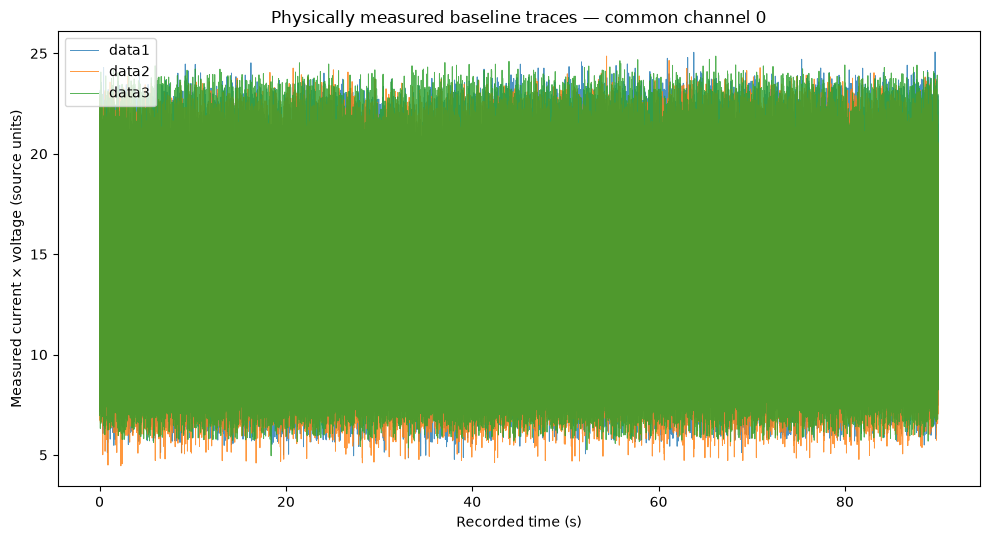

In [5]:
def load_lynsyn(path):
    path = Path(path)
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    header_idx = None
    for i, line in enumerate(lines):
        try:
            parts = next(csv.reader([line], delimiter=";"))
        except Exception:
            continue
        if parts and normalise_colname(parts[0]) == "time":
            header_idx = i
            break
    if header_idx is None:
        raise ValueError(f"{path}: could not locate a header row beginning with Time")

    df = pd.read_csv(path, sep=";", skiprows=header_idx, header=0)
    raw_headers = [str(c).strip() for c in df.columns]
    df.columns = [normalise_colname(c) for c in raw_headers]
    df.attrs["raw_headers"] = raw_headers
    df.attrs["header_line_1_based"] = header_idx + 1
    return df

def discover_current_voltage_pairs(df):
    currents, voltages = {}, {}
    for c in df.columns:
        m = re.fullmatch(r"current_(\d+)", c)
        if m:
            currents[int(m.group(1))] = c
        m = re.fullmatch(r"voltage_(\d+)", c)
        if m:
            voltages[int(m.group(1))] = c
    return [
        (idx, currents[idx], voltages[idx])
        for idx in sorted(set(currents) & set(voltages))
    ]

raw_frames = {}
sampling_rows = []
for dataset, path in RAW_TRACE_BY_DATASET.items():
    if path is None:
        continue
    df = load_lynsyn(path)
    raw_frames[dataset] = df
    if "time" not in df.columns:
        continue
    t = numeric(df["time"]).dropna().to_numpy()
    dt = np.diff(t)
    dt = dt[np.isfinite(dt) & (dt > 0)]
    sampling_rows.append({
        "dataset": dataset,
        "file": path.name,
        "n_samples": len(df),
        "duration_s": float(t[-1] - t[0]) if len(t) >= 2 else np.nan,
        "median_dt_s": float(np.median(dt)) if len(dt) else np.nan,
        "average_sampling_hz_from_duration":
            float((len(t)-1)/(t[-1]-t[0]))
            if len(t) >= 2 and t[-1] > t[0] else np.nan,
        "header_line_1_based": df.attrs.get("header_line_1_based"),
    })

raw_sampling = pd.DataFrame(sampling_rows)
raw_sampling.to_csv(TABLE_ROOT / "raw_sampling_evidence.csv", index=False)
display(raw_sampling)

# Raw Lynsyn traces are the physically measured baseline evidence.
# The current x voltage product is kept in source units because the export
# headers do not establish engineering-unit scaling.
baseline_rows = []
for dataset, df in raw_frames.items():
    if "time" not in df.columns:
        continue
    for idx, current_col, voltage_col in discover_current_voltage_pairs(df):
        y = numeric(df[current_col]) * numeric(df[voltage_col])
        baseline_rows.append({
            "dataset": dataset,
            "channel_index": idx,
            "n": int(y.notna().sum()),
            "mean_current_x_voltage": float(y.mean()),
            "std_current_x_voltage": float(y.std(ddof=1)),
            "median_current_x_voltage": float(y.median()),
        })

raw_baseline_summary = pd.DataFrame(baseline_rows)
raw_baseline_summary.to_csv(TABLE_ROOT / "physically_measured_baseline_trace_summary.csv", index=False)
display(raw_baseline_summary)

# One common-channel overview using the same axes for every trace.
common_channels = None
for df in raw_frames.values():
    ids = {idx for idx, _, _ in discover_current_voltage_pairs(df)}
    common_channels = ids if common_channels is None else common_channels & ids
common_channels = sorted(common_channels or [])

if common_channels:
    idx = common_channels[0]
    plt.figure(figsize=(10, 5.5))
    for dataset, df in raw_frames.items():
        pair_map = {i: (c, v) for i, c, v in discover_current_voltage_pairs(df)}
        c, v = pair_map[idx]
        t = numeric(df["time"])
        y = numeric(df[c]) * numeric(df[v])
        plt.plot(t, y, linewidth=0.7, alpha=0.8, label=dataset)
    plt.xlabel("Recorded time (s)")
    plt.ylabel("Measured current × voltage (source units)")
    plt.title(f"Physically measured baseline traces — common channel {idx}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / "baseline_trace_common_scale.png", dpi=300)
    plt.show()

## 5. Source-to-controlled comparison on the balanced verified subset

`source_power_data` and `observation_new` are paired quantities stored in the simulator result files. The former is the source/reference sequence derived from the input trace; the latter is the simulator-derived controlled output.

The comparison is therefore described as a **source-to-simulator-controlled reduction**, not as a direct physical measurement of controlled Jetson power.

In [6]:
def summarise_power_file(path):
    df = read_project_csv(path)
    required = {"source_power_data", "observation_new"}
    if not required.issubset(df.columns):
        return None

    source = numeric(df["source_power_data"])
    controlled = numeric(df["observation_new"])
    valid = source.notna() & controlled.notna()
    source = source[valid]
    controlled = controlled[valid]

    source_sum = float(source.sum()) if len(source) else np.nan
    controlled_sum = float(controlled.sum()) if len(controlled) else np.nan
    reduction = (
        100.0 * (source_sum - controlled_sum) / source_sum
        if np.isfinite(source_sum) and not np.isclose(source_sum, 0)
        else np.nan
    )

    row = {
        "n_paired_records": int(len(source)),
        "stored_source_mean": float(source.mean()) if len(source) else np.nan,
        "simulator_controlled_mean": float(controlled.mean()) if len(controlled) else np.nan,
        "paired_sample_reduction_pct": reduction,
        "recorded_efficiency_mean_pct":
            100.0 * float(numeric(df["efficiency"]).mean())
            if "efficiency" in df.columns else np.nan,
        "reward_mean":
            float(numeric(df["reward"]).mean())
            if "reward" in df.columns else np.nan,
        "has_embedded_header": bool(df.attrs.get("has_header")),
        "schema_source": df.attrs.get("schema_source"),
    }
    return row

def collect_verified_result_summaries(datasets):
    rows = []
    for dataset in datasets:
        for seed in EXPECTED_SEEDS:
            for algorithm in EXPECTED_ALGORITHMS:
                audit_row = evaluation_trace_audit[
                    (evaluation_trace_audit["dataset"] == dataset)
                    & (evaluation_trace_audit["seed"] == seed)
                    & (evaluation_trace_audit["algorithm"] == algorithm)
                ]
                if audit_row.empty or not bool(
                    audit_row["eligible_for_evaluation_analysis"].iloc[0]
                ):
                    continue
                path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_power.csv"
                summary = summarise_power_file(path)
                if summary is None:
                    continue
                rows.append({
                    "dataset": dataset,
                    "seed": seed,
                    "algorithm": algorithm,
                    "file": str(path.relative_to(ROOT)),
                    **summary,
                })
    return pd.DataFrame(rows)

In [7]:
verified_results = collect_verified_result_summaries(COMMON_VERIFIED_DATASETS)
verified_results.to_csv(TABLE_ROOT / "verified_common_dataset_file_summaries.csv",
                        index=False)
display(verified_results)

# Keep the one currently verified Data 1 evaluation separate.
data1_checkpoint_results = collect_verified_result_summaries(
    [d for d in DATASET_ROOTS if d.lower() == "data1"]
)
if not data1_checkpoint_results.empty:
    allowed = data1_verified_checkpoint[["dataset", "seed", "algorithm"]]
    data1_checkpoint_results = data1_checkpoint_results.merge(
        allowed, on=["dataset", "seed", "algorithm"], how="inner"
    )
data1_checkpoint_results.to_csv(
    TABLE_ROOT / "data1_verified_checkpoint_only.csv", index=False
)
display(data1_checkpoint_results)

# Balanced five-seed summaries: repeated verified datasets are averaged within seed.
metric_cols = [
    "recorded_efficiency_mean_pct",
    "paired_sample_reduction_pct",
    "reward_mean",
    "stored_source_mean",
    "simulator_controlled_mean",
]
metric_cols = [c for c in metric_cols if c in verified_results.columns]

if not verified_results.empty:
    seed_metrics = (
        verified_results
        .groupby(["seed", "algorithm"], as_index=False)[metric_cols]
        .mean(numeric_only=True)
    )
else:
    seed_metrics = pd.DataFrame()

seed_metrics.to_csv(TABLE_ROOT / "interim_seed_level_metrics_common_verified.csv",
                    index=False)
display(seed_metrics)

summary_rows = []
for algorithm, g in seed_metrics.groupby("algorithm"):
    for metric in metric_cols:
        values = g[metric].dropna()
        lo, hi = t_ci(values)
        summary_rows.append({
            "algorithm": algorithm,
            "metric": metric,
            "n_independent_seeds": len(values),
            "mean": float(values.mean()) if len(values) else np.nan,
            "std": float(values.std(ddof=1)) if len(values) > 1 else np.nan,
            "median": float(values.median()) if len(values) else np.nan,
            "ci95_low": lo,
            "ci95_high": hi,
            "analysis_scope":
                "interim; balanced fully verified datasets only; Data 1 pending",
        })
interim_summary = pd.DataFrame(summary_rows)
interim_summary.to_csv(
    TABLE_ROOT / "interim_seed_summary_mean_sd_ci.csv", index=False
)
display(interim_summary)

,dataset,seed,algorithm,file,n_paired_records,stored_source_mean,simulator_controlled_mean,paired_sample_reduction_pct,recorded_efficiency_mean_pct,reward_mean,has_embedded_header,schema_source
0,data2,200,ddpg,data2/200/ddpg_power.csv,47671,8.525144,4.872618,42.844151,41.826645,33.922720,False,extracted from analysis_all.ipynb
1,data2,200,ppo,data2/200/ppo_power.csv,159687,8.489497,4.730027,44.283779,37.109070,13.042702,False,extracted from analysis_all.ipynb
2,data2,200,sac,data2/200/sac_power.csv,47671,8.525144,4.829996,43.344109,42.450481,24.627635,False,extracted from analysis_all.ipynb
3,data2,200,td3,data2/200/td3_power.csv,47671,8.525144,4.927605,42.199159,40.852989,33.241614,False,extracted from analysis_all.ipynb
4,data2,200,trpo,data2/200/trpo_power.csv,47671,8.525144,5.611035,34.182513,32.081517,23.966017,False,extracted from analysis_all.ipynb
5,data2,345,ddpg,data2/345/ddpg_power.csv,47671,8.525144,5.056814,40.683531,39.311306,30.085188,False,extracted from analysis_all.ipynb
6,data2,345,ppo,data2/345/ppo_power.csv,159687,8.489497,4.801267,43.444617,36.301335,13.217619,False,extracted from analysis_all.ipynb
7,data2,345,sac,data2/345/sac_power.csv,47671,8.525144,4.804619,43.641782,42.787831,23.928720,False,extracted from analysis_all.ipynb
8,data2,345,td3,data2/345/td3_power.csv,47671,8.525144,5.030954,40.986868,39.122360,31.072686,False,extracted from analysis_all.ipynb
9,data2,345,trpo,data2/345/trpo_power.csv,47671,8.525144,5.820435,31.726252,28.371288,18.900023,False,extracted from analysis_all.ipynb


,dataset,seed,algorithm,file,n_paired_records,stored_source_mean,simulator_controlled_mean,paired_sample_reduction_pct,recorded_efficiency_mean_pct,reward_mean,has_embedded_header,schema_source
0,data1,1024,ppo,data1/1024/ppo_power.csv,159687,8.830615,5.857342,33.670055,22.757736,2.175763,False,extracted from analysis_all.ipynb


,seed,algorithm,recorded_efficiency_mean_pct,paired_sample_reduction_pct,reward_mean,stored_source_mean,simulator_controlled_mean
0,200,ddpg,41.199462,42.374528,32.954742,8.665791,4.994364
1,200,ppo,37.027954,44.017667,13.714845,8.660056,4.848555
2,200,sac,41.136121,42.167591,25.686203,8.665791,5.013291
3,200,td3,39.996356,41.476768,32.165793,8.665791,5.072517
4,200,trpo,32.656382,34.813005,25.844675,8.665791,5.648082
5,345,ddpg,40.636496,41.767979,31.464014,8.665791,5.044740
6,345,ppo,34.659813,41.457451,14.287813,8.660056,5.073207
7,345,sac,40.184005,41.441890,24.621646,8.665791,5.077618
8,345,td3,35.461543,38.130641,26.983743,8.665791,5.365487
9,345,trpo,32.208518,34.707406,23.477229,8.665791,5.653927


,algorithm,metric,n_independent_seeds,mean,std,median,ci95_low,ci95_high,analysis_scope
0,ddpg,recorded_efficiency_mean_pct,5,41.520257,0.803674,41.199462,40.522364,42.518150,interim; balanced fully verified datasets only...
1,ddpg,paired_sample_reduction_pct,5,42.496904,0.616045,42.374528,41.731983,43.261824,interim; balanced fully verified datasets only...
2,ddpg,reward_mean,5,32.377148,0.824184,32.908068,31.353788,33.400507,interim; balanced fully verified datasets only...
3,ddpg,stored_source_mean,5,8.665791,0.000000,8.665791,8.665791,8.665791,interim; balanced fully verified datasets only...
4,ddpg,simulator_controlled_mean,5,4.982960,0.051992,4.994364,4.918403,5.047516,interim; balanced fully verified datasets only...
5,ppo,recorded_efficiency_mean_pct,5,36.247917,1.056140,36.656287,34.936546,37.559288,interim; balanced fully verified datasets only...
6,ppo,paired_sample_reduction_pct,5,43.109767,1.062785,43.579255,41.790145,44.429389,interim; balanced fully verified datasets only...
7,ppo,reward_mean,5,14.131018,0.579689,14.287813,13.411239,14.850797,interim; balanced fully verified datasets only...
8,ppo,stored_source_mean,5,8.660056,0.000000,8.660056,8.660056,8.660056,interim; balanced fully verified datasets only...
9,ppo,simulator_controlled_mean,5,4.926071,0.093110,4.883417,4.810460,5.041683,interim; balanced fully verified datasets only...


## 6. Interim paired algorithm comparisons on independent seeds

In [8]:
paired_rows = []
for metric in [
    c for c in
    ["recorded_efficiency_mean_pct", "paired_sample_reduction_pct"]
    if c in seed_metrics.columns
]:
    wide = seed_metrics.pivot(index="seed", columns="algorithm", values=metric)
    for a, b in combinations(wide.columns, 2):
        pair = wide[[a, b]].dropna()
        diff = pair[a] - pair[b]
        sd = diff.std(ddof=1)
        paired_rows.append({
            "metric": metric,
            "algorithm_a": a,
            "algorithm_b": b,
            "n_paired_seeds": len(pair),
            "mean_difference_a_minus_b": float(diff.mean())
                if len(diff) else np.nan,
            "paired_effect_size_dz":
                float(diff.mean() / sd)
                if len(diff) > 1 and np.isfinite(sd) and sd > 0 else np.nan,
            "exact_two_sided_signflip_p":
                exact_signflip_pvalue(diff) if len(diff) >= 2 else np.nan,
        })

interim_paired = pd.DataFrame(paired_rows)
if not interim_paired.empty:
    interim_paired["holm_adjusted_p"] = np.nan
    for metric, idx in interim_paired.groupby("metric").groups.items():
        interim_paired.loc[idx, "holm_adjusted_p"] = holm_adjust(
            interim_paired.loc[idx, "exact_two_sided_signflip_p"]
        )

interim_paired.to_csv(
    TABLE_ROOT / "interim_paired_seed_comparisons.csv", index=False
)
display(interim_paired)

print(
    "Statistical warning: these are interim balanced-subset comparisons. "
    "Recompute the final statistics in Notebook 2 after Data 1 is fully verified."
)

,metric,algorithm_a,algorithm_b,n_paired_seeds,mean_difference_a_minus_b,paired_effect_size_dz,exact_two_sided_signflip_p,holm_adjusted_p
0,recorded_efficiency_mean_pct,ddpg,ppo,5,5.272340,4.245024,0.0625,0.625
1,recorded_efficiency_mean_pct,ddpg,sac,5,1.934211,0.760411,0.0625,0.625
2,recorded_efficiency_mean_pct,ddpg,td3,5,1.664510,0.813444,0.1250,0.625
3,recorded_efficiency_mean_pct,ddpg,trpo,5,9.409388,7.751718,0.0625,0.625
4,recorded_efficiency_mean_pct,ppo,sac,5,-3.338129,-1.901235,0.0625,0.625
5,recorded_efficiency_mean_pct,ppo,td3,5,-3.607830,-1.810013,0.0625,0.625
6,recorded_efficiency_mean_pct,ppo,trpo,5,4.137048,3.186536,0.0625,0.625
7,recorded_efficiency_mean_pct,sac,td3,5,-0.269701,-0.072199,0.7500,0.750
8,recorded_efficiency_mean_pct,sac,trpo,5,7.475177,3.841490,0.0625,0.625
9,recorded_efficiency_mean_pct,td3,trpo,5,7.744878,2.882533,0.0625,0.625


Statistical warning: these are interim balanced-subset comparisons. Recompute the final statistics in Notebook 2 after Data 1 is fully verified.


## 7. Publication figures using consistent scales

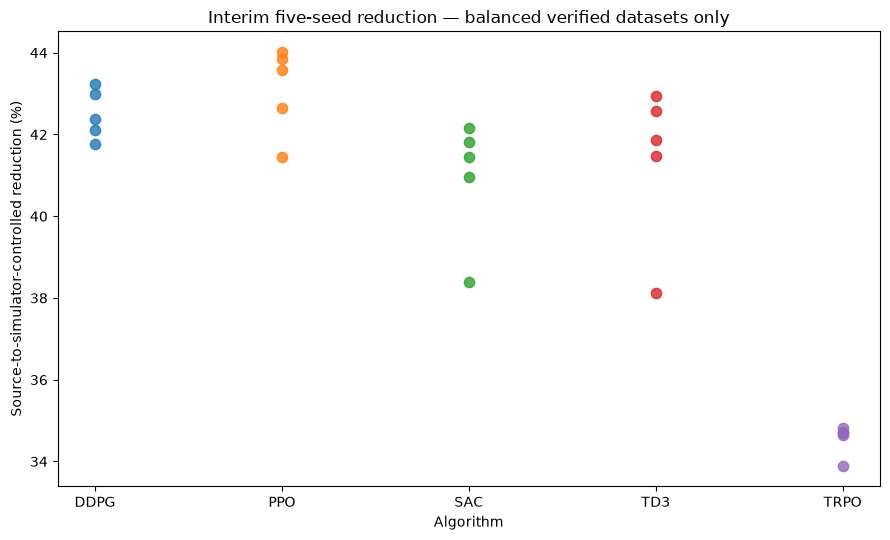

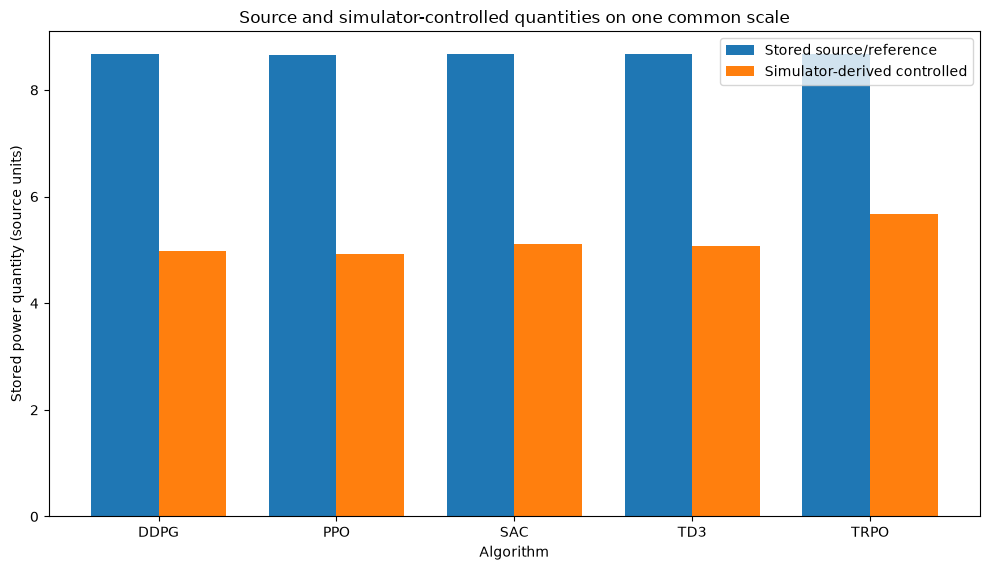

In [9]:
if not seed_metrics.empty and "paired_sample_reduction_pct" in seed_metrics.columns:
    plt.figure(figsize=(9, 5.5))
    for algorithm, g in seed_metrics.groupby("algorithm"):
        x = np.full(len(g), algorithm.upper(), dtype=object)
        plt.scatter(x, g["paired_sample_reduction_pct"], s=55, alpha=0.8)
    plt.ylabel("Source-to-simulator-controlled reduction (%)")
    plt.xlabel("Algorithm")
    plt.title("Interim five-seed reduction — balanced verified datasets only")
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / "interim_reduction_seed_points.png", dpi=300)
    plt.show()

if not seed_metrics.empty and {
    "stored_source_mean", "simulator_controlled_mean"
}.issubset(seed_metrics.columns):
    plot_rows = []
    for algorithm, g in seed_metrics.groupby("algorithm"):
        plot_rows.append({
            "algorithm": algorithm.upper(),
            "source": g["stored_source_mean"].mean(),
            "controlled": g["simulator_controlled_mean"].mean(),
        })
    plot_df = pd.DataFrame(plot_rows)
    xpos = np.arange(len(plot_df))
    width = 0.38
    plt.figure(figsize=(10, 5.8))
    plt.bar(xpos - width/2, plot_df["source"], width, label="Stored source/reference")
    plt.bar(xpos + width/2, plot_df["controlled"], width,
            label="Simulator-derived controlled")
    plt.xticks(xpos, plot_df["algorithm"])
    plt.ylabel("Stored power quantity (source units)")
    plt.xlabel("Algorithm")
    plt.title("Source and simulator-controlled quantities on one common scale")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / "source_vs_controlled_common_scale.png", dpi=300)
    plt.show()

## 8. Multi-seed training reward and adjusted-efficiency figures

The original analysis defines the adjusted efficiency as:

\[
E_{\mathrm{adjusted}} =
E_{\mathrm{epoch\ mean}}	imes p_{\mathrm{valid}},
\]

where `percentage` is the source-defined valid ratio.

The folder in which a training export is stored does **not** prove which physical trace was used for training. These figures therefore retain dataset-folder provenance and must not be used to claim a training-trace identity unless separate configuration records confirm it.

,algorithm,epoch,mean_adjusted_efficiency,std_adjusted_efficiency,ci95_low,ci95_high,n_seeds
0,ddpg,1,0.078053,0.112699,-0.061881,0.217988,5
1,ddpg,2,-0.161482,0.249735,-0.471569,0.148605,5
2,ddpg,3,-0.288050,0.322404,-0.688368,0.112268,5
3,ddpg,4,-0.264020,0.355328,-0.705218,0.177177,5
4,ddpg,5,-0.304014,0.254501,-0.620019,0.011990,5
5,ddpg,6,-0.316824,0.292888,-0.680493,0.046844,5
6,ddpg,7,-0.343620,0.331250,-0.754921,0.067681,5
7,ddpg,8,-0.388379,0.336832,-0.806611,0.029853,5
8,ddpg,9,-0.298394,0.293481,-0.662799,0.066011,5
9,ddpg,10,-0.194723,0.302894,-0.570815,0.181370,5


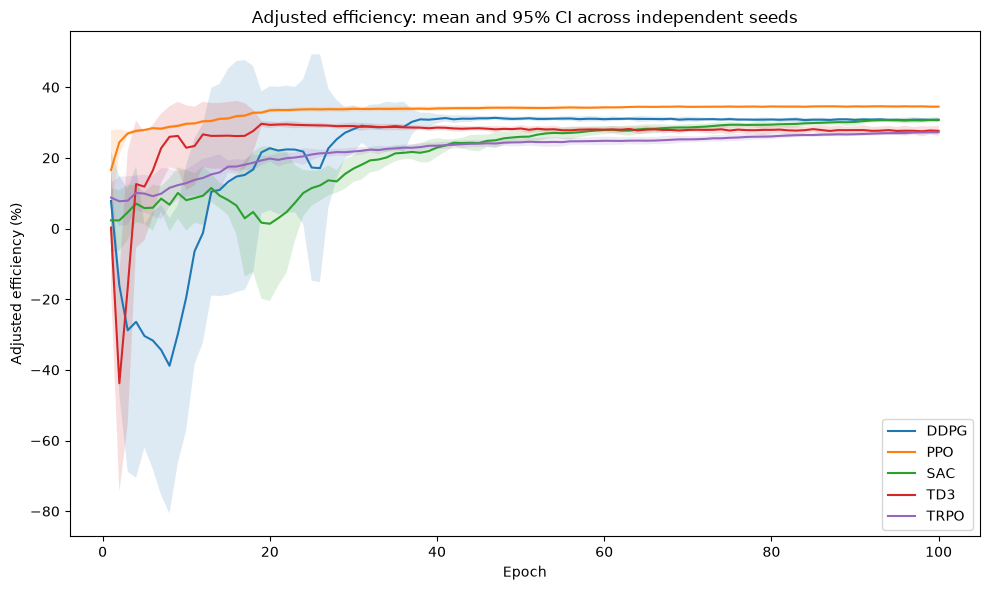

,algorithm,epoch,mean_reward,std_reward,ci95_low,ci95_high,n_seeds
0,ddpg,1,-21.267064,9.555471,-33.131749,-9.402380,5
1,ddpg,2,-18.808607,6.121776,-26.409796,-11.207418,5
2,ddpg,3,-15.659213,3.231203,-19.671282,-11.647144,5
3,ddpg,4,-13.492599,5.495571,-20.316252,-6.668947,5
4,ddpg,5,-14.114191,3.618606,-18.607283,-9.621098,5
5,ddpg,6,-14.658231,4.709543,-20.505901,-8.810561,5
6,ddpg,7,-14.285408,6.212613,-21.999386,-6.571431,5
7,ddpg,8,-15.098574,5.304803,-21.685356,-8.511792,5
8,ddpg,9,-13.659694,6.200318,-21.358406,-5.960982,5
9,ddpg,10,-12.270145,6.104280,-19.849610,-4.690681,5


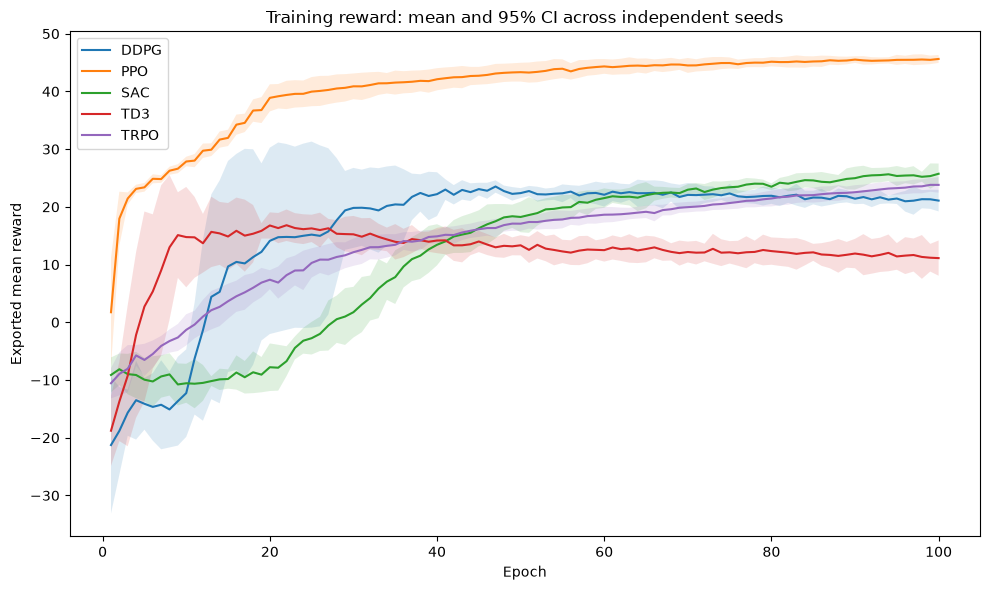

In [10]:
training_rows = []
reward_rows = []

for dataset in COMMON_VERIFIED_DATASETS:
    droot = DATASET_ROOTS[dataset]
    for seed in EXPECTED_SEEDS:
        sroot = droot / str(seed)
        for algorithm in EXPECTED_ALGORITHMS:
            eff_path = sroot / f"{algorithm}_efficiency.csv"
            if eff_path.exists():
                df = read_project_csv(eff_path)
                needed = {"epoch", "epoch_mean_efficiency", "percentage"}
                if needed.issubset(df.columns):
                    tmp = df[["epoch", "epoch_mean_efficiency", "percentage"]].copy()
                    tmp["epoch"] = numeric(tmp["epoch"])
                    tmp["epoch_mean_efficiency"] = numeric(tmp["epoch_mean_efficiency"])
                    tmp["percentage"] = numeric(tmp["percentage"])
                    tmp["adjusted_efficiency"] = (
                        tmp["epoch_mean_efficiency"] * tmp["percentage"]
                    )
                    tmp["dataset_folder"] = dataset
                    tmp["seed"] = seed
                    tmp["algorithm"] = algorithm
                    tmp["training_trace_identity_confirmed"] = False
                    training_rows.append(tmp)

        reward_path = droot / "save_figure" / str(seed) / "reward_epoch_mean_std_ci.csv"
        if reward_path.exists():
            rdf = read_project_csv(reward_path)
            if {"epoch", "algorithm", "mean"}.issubset(rdf.columns):
                tmp = rdf[["epoch", "algorithm", "mean"]].copy()
                tmp["epoch"] = numeric(tmp["epoch"])
                tmp["mean"] = numeric(tmp["mean"])
                tmp["algorithm"] = tmp["algorithm"].astype(str).str.lower()
                tmp["dataset_folder"] = dataset
                tmp["seed"] = seed
                tmp["training_trace_identity_confirmed"] = False
                reward_rows.append(tmp)

training = pd.concat(training_rows, ignore_index=True) if training_rows else pd.DataFrame()
reward_export = pd.concat(reward_rows, ignore_index=True) if reward_rows else pd.DataFrame()

training.to_csv(TABLE_ROOT / "training_export_audit.csv", index=False)
reward_export.to_csv(TABLE_ROOT / "reward_export_audit.csv", index=False)

# Average repeated dataset-folder exports within seed first.
if not training.empty:
    seed_epoch_eff = (
        training
        .groupby(["seed", "algorithm", "epoch"], as_index=False)[
            ["epoch_mean_efficiency", "percentage", "adjusted_efficiency"]
        ]
        .mean()
    )
    eff_summary_rows = []
    for (algorithm, epoch), g in seed_epoch_eff.groupby(["algorithm", "epoch"]):
        vals = g["adjusted_efficiency"].dropna()
        lo, hi = t_ci(vals)
        eff_summary_rows.append({
            "algorithm": algorithm,
            "epoch": epoch,
            "mean_adjusted_efficiency": vals.mean() if len(vals) else np.nan,
            "std_adjusted_efficiency": vals.std(ddof=1) if len(vals) > 1 else np.nan,
            "ci95_low": lo,
            "ci95_high": hi,
            "n_seeds": len(vals),
        })
    adjusted_efficiency_summary = pd.DataFrame(eff_summary_rows)
else:
    adjusted_efficiency_summary = pd.DataFrame()

adjusted_efficiency_summary.to_csv(
    TABLE_ROOT / "training_adjusted_efficiency_across_seeds.csv", index=False
)
display(adjusted_efficiency_summary.head(20))

if not adjusted_efficiency_summary.empty:
    plt.figure(figsize=(10, 6))
    for algorithm, g in adjusted_efficiency_summary.groupby("algorithm"):
        g = g.sort_values("epoch")
        x = g["epoch"].to_numpy(dtype=float)
        y = 100.0 * g["mean_adjusted_efficiency"].to_numpy(dtype=float)
        lo = 100.0 * g["ci95_low"].to_numpy(dtype=float)
        hi = 100.0 * g["ci95_high"].to_numpy(dtype=float)
        plt.plot(x, y, label=algorithm.upper())
        plt.fill_between(x, lo, hi, alpha=0.15)
    plt.xlabel("Epoch")
    plt.ylabel("Adjusted efficiency (%)")
    plt.title("Adjusted efficiency: mean and 95% CI across independent seeds")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / "training_adjusted_efficiency_across_seeds.png",
                dpi=300)
    plt.show()

if not reward_export.empty:
    reward_seed = (
        reward_export
        .groupby(["seed", "algorithm", "epoch"], as_index=False)["mean"]
        .mean()
    )
    reward_summary_rows = []
    for (algorithm, epoch), g in reward_seed.groupby(["algorithm", "epoch"]):
        vals = g["mean"].dropna()
        lo, hi = t_ci(vals)
        reward_summary_rows.append({
            "algorithm": algorithm,
            "epoch": epoch,
            "mean_reward": vals.mean() if len(vals) else np.nan,
            "std_reward": vals.std(ddof=1) if len(vals) > 1 else np.nan,
            "ci95_low": lo,
            "ci95_high": hi,
            "n_seeds": len(vals),
        })
    reward_summary = pd.DataFrame(reward_summary_rows)
else:
    reward_summary = pd.DataFrame()

reward_summary.to_csv(
    TABLE_ROOT / "training_reward_across_seeds.csv", index=False
)
display(reward_summary.head(20))

if not reward_summary.empty:
    plt.figure(figsize=(10, 6))
    for algorithm, g in reward_summary.groupby("algorithm"):
        g = g.sort_values("epoch")
        x = g["epoch"].to_numpy(dtype=float)
        y = g["mean_reward"].to_numpy(dtype=float)
        lo = g["ci95_low"].to_numpy(dtype=float)
        hi = g["ci95_high"].to_numpy(dtype=float)
        plt.plot(x, y, label=algorithm.upper())
        plt.fill_between(x, lo, hi, alpha=0.15)
    plt.xlabel("Epoch")
    plt.ylabel("Exported mean reward")
    plt.title("Training reward: mean and 95% CI across independent seeds")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / "training_reward_across_seeds.png", dpi=300)
    plt.show()

## 9. Conditional controller-overhead break-even analysis

Actual controller-only energy was not measured. The existing gross source-to-controlled reduction can nevertheless define a **conditional break-even overhead budget**: the controller could consume at most the gross saving before the net saving becomes zero.

This is a bound/scenario analysis, not an overhead measurement.

In [11]:
break_even_rows = []
if not seed_metrics.empty and "paired_sample_reduction_pct" in seed_metrics.columns:
    for algorithm, g in seed_metrics.groupby("algorithm"):
        vals = g["paired_sample_reduction_pct"].dropna()
        lo, hi = t_ci(vals)
        break_even_rows.append({
            "algorithm": algorithm,
            "n_seeds": len(vals),
            "mean_break_even_overhead_pct_of_source": vals.mean()
                if len(vals) else np.nan,
            "minimum_observed_seed_break_even_pct": vals.min()
                if len(vals) else np.nan,
            "maximum_observed_seed_break_even_pct": vals.max()
                if len(vals) else np.nan,
            "ci95_low": lo,
            "ci95_high": hi,
            "interpretation":
                "conditional ceiling; actual controller overhead not measured",
        })

break_even = pd.DataFrame(break_even_rows)
break_even.to_csv(
    TABLE_ROOT / "conditional_controller_overhead_break_even.csv", index=False
)
display(break_even)

scenario_rows = []
for _, row in break_even.iterrows():
    for assumed_overhead_pct in [0, 2, 5, 10, 20, 30]:
        scenario_rows.append({
            "algorithm": row["algorithm"],
            "assumed_controller_overhead_pct_of_source": assumed_overhead_pct,
            "conditional_net_reduction_pct":
                row["mean_break_even_overhead_pct_of_source"]
                - assumed_overhead_pct,
        })
overhead_scenarios = pd.DataFrame(scenario_rows)
overhead_scenarios.to_csv(
    TABLE_ROOT / "conditional_overhead_sensitivity.csv", index=False
)
display(overhead_scenarios)

,algorithm,n_seeds,mean_break_even_overhead_pct_of_source,minimum_observed_seed_break_even_pct,maximum_observed_seed_break_even_pct,ci95_low,ci95_high,interpretation
0,ddpg,5,42.496904,41.767979,43.246326,41.731983,43.261824,conditional ceiling; actual controller overhea...
1,ppo,5,43.109767,41.457451,44.017667,41.790145,44.429389,conditional ceiling; actual controller overhea...
2,sac,5,40.950992,38.384829,42.167591,39.084561,42.817423,conditional ceiling; actual controller overhea...
3,td3,5,41.396533,38.130641,42.951331,39.018367,43.774700,conditional ceiling; actual controller overhea...
4,trpo,5,34.554906,33.893677,34.813005,34.090003,35.019809,conditional ceiling; actual controller overhea...


,algorithm,assumed_controller_overhead_pct_of_source,conditional_net_reduction_pct
0,ddpg,0,42.496904
1,ddpg,2,40.496904
2,ddpg,5,37.496904
3,ddpg,10,32.496904
4,ddpg,20,22.496904
5,ddpg,30,12.496904
6,ppo,0,43.109767
7,ppo,2,41.109767
8,ppo,5,38.109767
9,ppo,10,33.109767


## 10. First-revision manuscript claim table

In [12]:
claim_rows = [
    {
        "topic": "Experimental scope",
        "status": "SUPPORTED WITH NARROWED SCOPE",
        "manuscript_action":
            "Describe a fixed-configuration YOLOv4/Jetson TX2 case study. "
            "Do not claim cross-resolution, cross-CNN or cross-hardware validation.",
    },
    {
        "topic": "Data 1",
        "status": "INCOMPLETE",
        "manuscript_action":
            "Do not use Data 1 cross-algorithm summaries until the remaining "
            "24 algorithm-seed combinations are verified against Trace 1.",
    },
    {
        "topic": "Data 2 and Data 3",
        "status": "USABLE FOR BALANCED INTERIM ANALYSIS",
        "manuscript_action":
            "Use for first-revision interim statistical summaries; replace with "
            "the frozen all-dataset results after Data 1 completion.",
    },
    {
        "topic": "Baseline versus controlled power",
        "status": "SUPPORTED WITH TERMINOLOGY LIMIT",
        "manuscript_action":
            "Distinguish physically measured Lynsyn baseline traces from "
            "simulator-derived controlled-power quantities.",
    },
    {
        "topic": "Training trace identity",
        "status": "NOT ESTABLISHED BY FOLDER/EVALUATION TRACE",
        "manuscript_action":
            "State training trace identity only where configuration records prove it.",
    },
    {
        "topic": "Statistical superiority",
        "status": "DO NOT CLAIM UNIVERSALLY",
        "manuscript_action":
            "Report mean, SD, 95% CI, exact paired tests and effect sizes. "
            "Do not claim universal PPO superiority from five seeds.",
    },
    {
        "topic": "FPS/latency preservation",
        "status": "NOT MEASURED IN CURRENT DATA",
        "manuscript_action":
            "Remove measured preservation claims; retain as limitation/future work.",
    },
    {
        "topic": "Controller overhead",
        "status": "BOUND ONLY",
        "manuscript_action":
            "Present break-even overhead only as a conditional estimate based on "
            "gross simulator reduction; do not call it measured overhead.",
    },
    {
        "topic": "New ablations/resolutions/CNNs/platforms",
        "status": "OUT OF CURRENT SUBMISSION SCOPE",
        "manuscript_action":
            "Move to limitations/future work, as agreed in the revision sequence.",
    },
]
first_revision_claims = pd.DataFrame(claim_rows)
first_revision_claims.to_csv(
    TABLE_ROOT / "first_revision_claim_table.csv", index=False
)
display(first_revision_claims)

,topic,status,manuscript_action
0,Experimental scope,SUPPORTED WITH NARROWED SCOPE,Describe a fixed-configuration YOLOv4/Jetson T...
1,Data 1,INCOMPLETE,Do not use Data 1 cross-algorithm summaries un...
2,Data 2 and Data 3,USABLE FOR BALANCED INTERIM ANALYSIS,Use for first-revision interim statistical sum...
3,Baseline versus controlled power,SUPPORTED WITH TERMINOLOGY LIMIT,Distinguish physically measured Lynsyn baselin...
4,Training trace identity,NOT ESTABLISHED BY FOLDER/EVALUATION TRACE,State training trace identity only where confi...
5,Statistical superiority,DO NOT CLAIM UNIVERSALLY,"Report mean, SD, 95% CI, exact paired tests an..."
6,FPS/latency preservation,NOT MEASURED IN CURRENT DATA,Remove measured preservation claims; retain as...
7,Controller overhead,BOUND ONLY,Present break-even overhead only as a conditio...
8,New ablations/resolutions/CNNs/platforms,OUT OF CURRENT SUBMISSION SCOPE,"Move to limitations/future work, as agreed in ..."


## 11. Output index and hand-off to the second revision

In [13]:
print("First-revision analysis complete.")
print("Tables:", TABLE_ROOT)
print("Figures:", FIGURE_ROOT)
print()
print("Before running Notebook 2:")
print("  1. Complete/recover the remaining 24 Data 1 algorithm-seed outputs.")
print("  2. Verify each corrected Data 1 evaluation against lynsyn_data1.txt.")
print("  3. Create/update ROOT/evaluation_trace_verification.csv and mark only")
print("     genuinely verified combinations as verification_status='verified'.")
print("  4. Freeze the corrected dataset.")
print("  5. Run 02_second_revision_frozen_dataset_analysis.ipynb.")

First-revision analysis complete.
Tables: /home/pedro/repo/Zheqi_Results/test/revision1_fixed_yolov4_analysis/tables
Figures: /home/pedro/repo/Zheqi_Results/test/revision1_fixed_yolov4_analysis/figures

Before running Notebook 2:
  1. Complete/recover the remaining 24 Data 1 algorithm-seed outputs.
  2. Verify each corrected Data 1 evaluation against lynsyn_data1.txt.
  3. Create/update ROOT/evaluation_trace_verification.csv and mark only
     genuinely verified combinations as verification_status='verified'.
  4. Freeze the corrected dataset.
  5. Run 02_second_revision_frozen_dataset_analysis.ipynb.
